# Performing curation and analyze iModulons that might be associated with ethanol production.

- For this, I am assigning the required metadata (ethanol production) to the conditions/projects of choice.
- Then, I will check which iMods are increasing or decreasing for this specific phenotype.
- Once correlation analyses provides the preliminary set of IMs, OLS is performed to find the IM combinations that provide the best scores -- AIC and R2. VIF scores are used as guides to support the results.

In [ ]:
from pymodulon.io import *

import os
from os import path

import pandas as pd
import numpy as np

from model_selection_corr_ols import * #custom functions

import matplotlib.pyplot as plt

import seaborn as sns

import sklearn
sklearn.__version__

statsmodel version: 0.14.5
scipy version: 1.13.1


'1.0.2'

In [3]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

### path to different data

In [ ]:
data_dir = path.join('..', 'ctherm_nf','processed_data')

### different required data need to be loaded

In [ ]:
ica_data = load_json_model(path.join(data_dir, 'ctherm.json.gz')) #refined icadata object

### gene info
df_gene_info = pd.read_csv(path.join(data_dir, 'gene_info.csv'), index_col=0)
df_gene_info.head()

/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/p

### First rename the imodulon

In [8]:
df_rename_imod = pd.read_csv('./results_characterize_imodulons/imod_rename_mapping.tsv', sep='\t', index_col=0)
dict_rename_imod = df_rename_imod[['IM']].to_dict()['IM']

# rename all at once
ica_data.rename_imodulons(dict_rename_imod)

# set IM as index for this work
df_rename_imod.set_index('IM', inplace=True)

# GRN for regulation in C. thermocellum
for i,row in ica_data.imodulon_table.iterrows():
    if pd.notnull(row.regulator):
        ica_data.imodulon_table.loc[i, 'category'] = 'regulatory'
    else:
        ica_data.imodulon_table.loc[i, 'category'] = df_rename_imod.loc[i, 'category']



### Generating two different dataframes for metadata and expression (log normalized and with reference)

In [9]:
df_metadata = ica_data.sample_table
df_expression = ica_data.X

### Load the data to identify significant IMs. This contains samples per experiment. Replicates are averaged out

In [ ]:
df_imod_activity_eth_collapsed = pd.read_csv('./required_data/df_results_collapsed_exp_eh_evo.tsv', sep='\t', index_col=0)

In [ ]:
# spearman_filter is a function that is written in the model_selection_corr_ols.py file.
# The function computes Spearman correlation between each IM and ethanol on condition-collapsed data (one row per condition).
df_spearman, significant_ims, significant_ims_fdr = spearman_filter(df_imod_activity_eth_collapsed, ica_data.imodulon_names, 'Ethanol_g_L', rho_threshold=0.6)

# save the correlation table to a file, if needed
# df_spearman.to_csv('./results_characterize_imodulons/df_spearmanr_IM_ethanol_exp_eh_evo.tsv', sep='\t')


Spearman Effect Size Filter (|rho| > 0.6)
              IM  spearman_rho     pval     qval  strong_effect  passes_strong_effect  passes_all
         Sulfate     -0.722807 0.000472 0.024924           True                  True        True
    AbrB-Related     -0.705263 0.000744 0.024924           True                  True        True
           SigI6      0.631579 0.003726 0.078418           True                  True       False
    Fe-S-Related      0.617544 0.004843 0.078418           True                  True       False
      Co/Ni-tp-1      0.603509 0.006222 0.078418           True                  True       False
      Ribosome-1     -0.596491 0.007023 0.078418          False                 False       False
Sulfur/Porphyrin     -0.571930 0.010511 0.100603          False                 False       False
         Pentose     -0.552632 0.014135 0.118379          False                 False       False
            UC-8      0.538596 0.017351 0.129166          False            

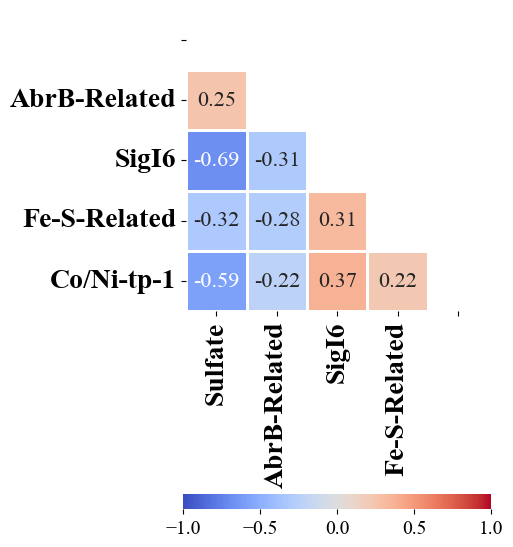

In [ ]:
# change the order
# significant_ims = ['Sulfate', 'AbrB-Related', 'Sigma-16', 'Fe-S-Related', 'Co/Ni-tp-1']#, 'Iron-1']

# checking for correlation
corr_matrix = df_activity.T[significant_ims].corr()

# Create a mask to hide the upper triangle
# np.triu returns True for elements on and above the diagonal
# If you want to KEEP the diagonal, add the parameter k=1
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 4. Set up the Matplotlib figure
fig, ax = plt.subplots(figsize=(8, 6))

# 5. Draw the heatmap with the mask
ax = sns.heatmap(
    corr_matrix, 
    mask=mask,          # Applies the upper-triangle mask
    cmap='coolwarm',    # Good colormap for positive/negative correlations
    cbar_kws={"orientation": "horizontal", 'shrink': 0.4, 'pad':0.32},
    vmax=1, vmin=-1, # Forces colorbar boundaries from -1 to 1
    annot=True,         # Shows the actual correlation numbers
    annot_kws={"fontsize": 16},
    square=True,        # Makes each cell perfectly square
    linewidths=0.9      # Adds thin borders between squares
)

# Access the colorbar object
cbar = ax.collections[0].colorbar

# Rotate y-tick labels by 45 degrees
cbar.ax.tick_params(labelsize=14)

# For X-axis
positions, labels = plt.xticks()
plt.xticks(ticks=positions, labels=labels[0:-1] + [''], fontweight='bold', size=20, rotation=90)
# For Y-axis
positions, labels = plt.yticks()
plt.yticks(ticks=positions, labels=[''] + labels[1:], fontweight='bold', size=20, rotation=0)

plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/corr_plot_sig_ims_etoh_prod.png', transparent=False, pad_inches=0.01, dpi=300, format='png')

plt.show()

### Now performing OLS modeling for all combinations of significant IMs -- LOO is also computed by the function compare_ols_combinations

In [ ]:
df_exp_imod_activity_eth_train = df_imod_activity_eth_collapsed[significant_ims]
# df_exp_imod_activity_eth_train = df_exp_imod_activity_eth_train.loc[df_exp_imod_activity_eth_train.index.str.startswith('eh_chemostat')]
df_exp_imod_activity_eth_train['Ethanol_g_L'] = df_imod_activity_eth_collapsed['Ethanol_g_L']

target_col = 'Ethanol_g_L'
summary, best_model = compare_ols_combinations(
    df         = df_exp_imod_activity_eth_train.copy(),
    im_cols    = significant_ims,
    target_col = target_col,
    loo        = True
)

# save the data for the OLS combinations
# summary.to_csv('./results_characterize_imodulons/ols_model_combination_results.tsv', sep='\t')

Testing 31 model combinations...
Data: 19 conditions, 5 candidate IMs

OLS Model Comparison — All Combinations (sorted by AIC)
                                                         model  n_ims  R2_adj  LOO_CV_R2     gap    AIC    F_pval  max_VIF  n_sig_ims
0                                       Sulfate + AbrB-Related      2  0.6053     0.5089  0.0963 -6.364  0.000230     1.69          1
1                          Sulfate + AbrB-Related + Co/Ni-tp-1      3  0.6126     0.5321  0.0805 -5.947  0.000569     2.27          0
2                            AbrB-Related + SigI6 + Co/Ni-tp-1      3  0.6063     0.5004  0.1060 -5.643  0.000640     1.67          1
3                        Sulfate + AbrB-Related + Fe-S-Related      3  0.5863     0.4401  0.1463 -4.701  0.000918     1.78          1
4                               Sulfate + AbrB-Related + SigI6      3  0.5831     0.4166  0.1665 -4.551  0.000972     4.11          0
5           Sulfate + AbrB-Related + Fe-S-Related + Co/Ni-tp-1      4

In [ ]:
# Full statsmodels summary of winner -- Best model
model = refit_best_model(df_exp_imod_activity_eth_train, best_model, target_col)

# print summary of the best model
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            Ethanol_g_L   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     14.80
Date:                Thu, 02 Jul 2026   Prob (F-statistic):           0.000230
Time:                        12:43:06   Log-Likelihood:                 6.1821
No. Observations:                  19   AIC:                            -6.364
Df Residuals:                      16   BIC:                            -3.531
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.6914      0.071      9.796      0.000       0.542       0.841
Sulfate         -0.0805      0.030     -2.647      0.018      -0.145      -0.016
AbrB-Related    -0.0583      0.030     -1.963      0.067      -0.121       0.005
==============================================================================
Omnibus:                        2.255   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.324   Jarque-Bera (JB):                1.232
Skew:                          -0.280   Prob(JB):                        0.540
Kurtosis:                       1.885   Cond. No.                         6.40
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### FIN